In [1]:
n = 2
N = 2**n

In [3]:
k = 3

from qiskit import quantum_info as qi
psi = qi.Statevector.from_int(k, dims=N)

from qiskit.visualization import array_to_latex
array_to_latex(psi)

<IPython.core.display.Latex object>

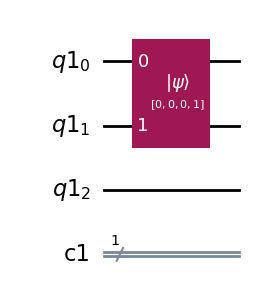

In [5]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import Initialize

qr = QuantumRegister(n+1)
cr = ClassicalRegister(1)
qc = QuantumCircuit(qr, cr)
init_gate = Initialize(psi)
qc.append(init_gate, qr[:n])
qc.draw('mpl')

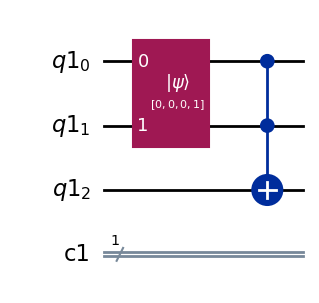

In [6]:
qc.ccx(qr[0], qr[1], qr[2])
qc.draw('mpl')

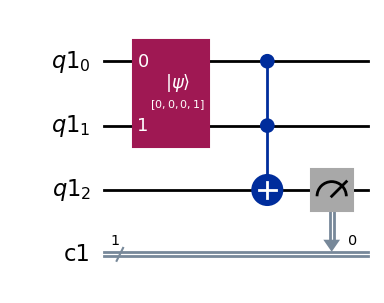

In [7]:
qc.measure(qr[2], cr)
qc.draw('mpl')

In [9]:
from qiskit_aer import Aer

backend = Aer.get_backend('qasm_simulator')
job = backend.run(qc, shots=100)
counts = job.result().get_counts()
print(counts)

{'1': 100}


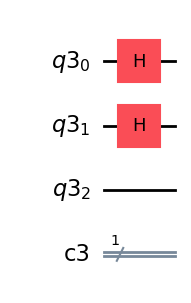

In [11]:
qr = QuantumRegister(n+1)
cr = ClassicalRegister(1)
qc = QuantumCircuit(qr, cr)
qc.h(qr[:n])
qc.draw('mpl')

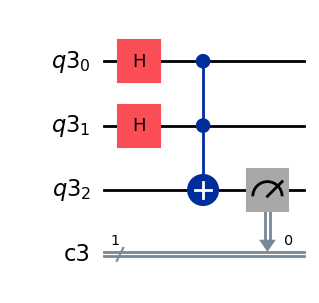

In [12]:
qc.ccx(qr[0], qr[1], qr[2])
qc.measure(qr[n], cr)
qc.draw('mpl')

In [13]:
counts = backend.run(qc, shots=1000).result().get_counts()

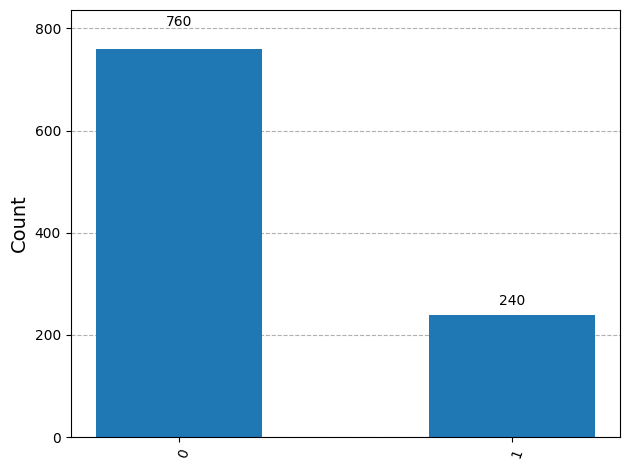

In [14]:
from qiskit.visualization import plot_histogram

plot_histogram(counts)

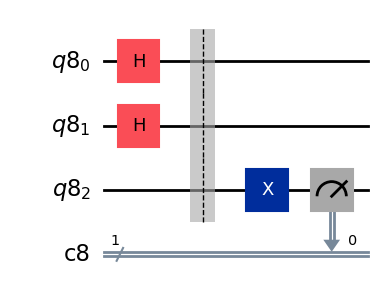

In [20]:
qr = QuantumRegister(n+1)
cr = ClassicalRegister(1)
qc = QuantumCircuit(qr, cr)
qc.h(qr[:n])
qc.barrier()
qc.x(qr[n])
qc.measure(qr[n], cr)
qc.draw('mpl')

In [21]:
counts = backend.run(qc, shots=1000).result().get_counts()
print(counts)

{'1': 1000}


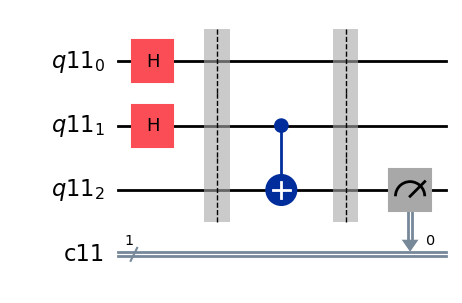

In [25]:
a = 2

qr = QuantumRegister(n+1)
cr = ClassicalRegister(1)
qc = QuantumCircuit(qr, cr)
qc.h(qr[:n])
qc.barrier()

for i in range(n):
    if (a & (1 << i)):
        qc.cx(qr[i], qr[n])

qc.barrier()
qc.measure(qr[n], cr)
qc.draw('mpl')

In [26]:
counts = backend.run(qc, shots=1000).result().get_counts()
print(counts)

{'0': 498, '1': 502}


In [41]:
a = 3

qr = QuantumRegister(n+1)
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.h(qr[:n])
qc.x(qr[n])
qc.h(qr[n])
qc.barrier()

#for i in range(n):
#    if (a & (1 << i)):
#        qc.cx(qr[i], qr[n])

qc.x(qr[n])

qc.barrier()

for i in range(n):
    qc.h(qr[i])

for i in range(n):
    qc.measure(qr[i], cr[i])

qc.draw()

┌───┐      ░       ░ ┌───┐┌─┐   
q19_0: ┤ H ├──────░───────░─┤ H ├┤M├───
       ├───┤      ░       ░ ├───┤└╥┘┌─┐
q19_1: ┤ H ├──────░───────░─┤ H ├─╫─┤M├
       ├───┤┌───┐ ░ ┌───┐ ░ └───┘ ║ └╥┘
q19_2: ┤ X ├┤ H ├─░─┤ X ├─░───────╫──╫─
       └───┘└───┘ ░ └───┘ ░       ║  ║ 
c19: 2/═══════════════════════════╩══╩═
                                  0  1

In [43]:
counts = backend.run(qc, shots=1).result().get_counts()
print(counts)

{'00': 1}
